## A Data-Driven Analysis of Phishing Website Characteristics using Python

## Dataset Information

Dataset Name: PhiUSIIL Phishing URL Dataset

Source: UCI Machine Learning Repository
 https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset

Location: Online websites and their URLs. The dataset is not limited to one specific geographic region.

Year/Timeline: The exact data collection period should be confirmed from the dataset documentation. A specific collection year range is not assumed.

Domain: Cybersecurity / Information Security



# Project Objectives

The main objective of this project is to perform Exploratory Data Analysis (EDA) on the PhiUSIIL Phishing URL Dataset using Python to identify patterns and characteristics associated with phishing and legitimate websites.

The specific objectives are:

1. To investigate URL and domain length patterns between phishing and legitimate websites.

2. To analyze URL obfuscation, digit usage, and special characters to identify differences between phishing and legitimate URLs.

3. To examine the relationship between subdomain counts and website classification.

4. To compare URL similarity scores and domain-title matching scores across phishing and legitimate websites.

5. To analyze website features such as titles, favicons, descriptions, and password fields across phishing and legitimate websites.

6. To examine HTTPS usage and other URL-related security indicators across phishing and legitimate websites.

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Load the Data Set from GitHub

url = "https://raw.githubusercontent.com/xlentguru04-ops/Phishing-Website-URL-Detection-Analysis_/main/PhiUSIIL_Phishing_URL_Dataset%20sample.csv"

df = pd.read_csv(url)

# Display the first five rows
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [ ]:
# Initial EDA: Dataset Dimensions and Sample Records

# Display the number of rows and columns
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])



Number of Rows: 49999
Number of Columns: 56


In [ ]:
# Display the first five records
print("\nFirst 5 Records:")
display(df.head())




First 5 Records:


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [ ]:
# Display five random records
print("\n5 Random Records:")
display(df.sample(5, random_state=42))


5 Random Records:


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
33552,oph00555.txt,http://043200.vip/,18,043200.vip,10,0,vip,50.545455,1.000000,0.000107,0.012025,3,0,0,0,0.0,3,0.167,6,0.333,0,0,0,2,0.111,0,4,58,0,0,16.666667,16.666667,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0
9427,8017992.txt,https://bpostceles.firebaseapp.com/,34,bpostceles.firebaseapp.com,26,0,com,69.508132,0.545455,0.522907,0.060781,3,1,0,0,0.0,24,0.706,0,0.000,0,0,0,2,0.059,1,18,100,1,bpostcelesfirebaseapp,0.000000,0.000000,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0
199,105348.txt,https://www.ichijinsha.co.jp,27,www.ichijinsha.co.jp,20,0,jp,100.000000,0.846154,0.023045,0.053200,2,2,0,0,0.0,13,0.481,0,0.000,0,0,0,2,0.074,1,591,344,1,ichiinshaco,0.000000,0.000000,0,0,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,36,5,8,48,0,50,1
12447,oph00967.txt,http://status-review-100256681991.firebaseapp....,50,status-review-100256681991.firebaseapp.com,42,0,com,43.492797,0.631579,0.522907,0.040132,3,1,0,0,0.0,26,0.520,12,0.240,0,0,0,5,0.100,0,2,59,0,0,2.631579,2.631579,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
39488,763801.txt,https://www.instantocean.com,27,www.instantocean.com,20,0,com,100.000000,1.000000,0.522907,0.071766,3,1,0,0,0.0,14,0.519,0,0.000,0,0,0,1,0.037,1,312,2125,1,instantocean,100.000000,100.000000,1,0,1,1,1,1,0,2,0,1,1,1,0,0,0,0,1,5,3,9,20,5,30,1


In [ ]:
# Data types and non-null counts
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49999 entries, 0 to 49998
Data columns (total 56 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   FILENAME                    49999 non-null  object 
 1   URL                         49999 non-null  object 
 2   URLLength                   49999 non-null  int64  
 3   Domain                      49999 non-null  object 
 4   DomainLength                49999 non-null  int64  
 5   IsDomainIP                  49999 non-null  int64  
 6   TLD                         49999 non-null  object 
 7   URLSimilarityIndex          49999 non-null  float64
 8   CharContinuationRate        49999 non-null  float64
 9   TLDLegitimateProb           49999 non-null  float64
 10  URLCharProb                 49999 non-null  float64
 11  TLDLength                   49999 non-null  int64  
 12  NoOfSubDomain               49999 non-null  int64  
 13  HasObfusca

In [ ]:

# Total missing values in the dataset
print("\nTotal missing values:", df.isnull().sum().sum())


Total missing values: 0


In [ ]:
# Summary for categorical / Boolean columns

print("Summary for categorical / Boolean columns:")

df.describe(include=['object', 'bool'])

Summary for categorical / Boolean columns:


,FILENAME,URL,Domain,TLD,Title
count,49999,49999,49999,49999,49999
unique,49999,49987,48475,451,42436
top,521848.txt,http://kocinlugingxnnicx.godaddysites.com/,ipfs.io,com,0
freq,1,2,178,24180,7301


In [ ]:
# Statistical summary of numerical columns

print("Statistical Summary of Numerical Columns:")

df.describe()

Statistical Summary of Numerical Columns:


,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,4.999900e+04,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000
mean,32.821216,21.102442,0.001880,80.482836,0.857711,0.263974,0.056232,2.760015,1.168083,0.001760,0.012120,0.000104,18.059481,0.508115,1.567391,0.025656,0.047801,0.024220,0.015780,2.144623,0.061072,0.757815,1173.871717,9.876677e+03,0.854077,52.472778,54.104693,0.364527,0.264545,0.616752,0.131463,0.041441,0.450109,0.225805,1.642933,0.044221,0.467809,0.417528,0.376308,0.098582,0.125523,0.237185,0.024560,0.491630,26.879958,6.200344,10.690114,65.715514,2.393108,49.310906,0.587492
std,38.030099,8.512614,0.043319,27.342968,0.209380,0.251382,0.010438,0.586824,0.569422,0.041916,0.378812,0.003154,30.352842,0.119915,7.372627,0.068765,0.507548,0.174684,0.410533,2.685069,0.031077,0.428410,3825.507632,1.006667e+05,0.353032,49.596591,49.454041,0.481302,0.441095,0.486183,0.337909,0.199310,0.497510,3.760104,4.954617,0.205588,0.498968,0.493156,0.484463,0.298103,0.331314,0.425361,0.154783,0.499935,79.522270,11.481700,17.778694,128.220625,13.441564,107.871204,0.492291
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,0.001223,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.300000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,61.948529,0.714286,0.006970,0.051695,2.000000,1.000000,0.000000,0.000000,0.000000,10.000000,0.435000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.038000,1.000000,15.000000,1.830000e+02,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,0.058353,3.000000,1.000000,0.000000,0.000000,0.000000,14.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.048000,1.000000,466.000000,1.018000e+03,1.000000,100.000000,100.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,2.000000,6.000000,16.000000,0.000000,11.000000,1.000000
75%,33.000000,24.000000,0.000000,100.000000,1.000000,0.522907,0.063148,3.000000,1.000000,0.000000,0.000000,0.000000,19.000000,0.581000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.080000,1.000000,1309.000000,8.04700

In [ ]:

# Identify numerical and categorical columns

numerical_columns = df.select_dtypes(include=['number']).columns.tolist()
categorical_columns = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nTotal Numerical Columns:", len(numerical_columns))

print("\nCategorical Columns:")
print(categorical_columns)

print("\nTotal Categorical Columns:", len(categorical_columns))


Numerical Columns:
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

Total Numerical Columns: 51

Categorical Columns:
['FILENAME', 'URL', 'Domain', 'TLD', 'Title']

Total Cat

# Stage 2

## Data Cleaning & Preprocessing

### Data Cleaning, Data Transformation and Feature Engineering

- Handle Duplicates
- Handle Missing Values
- Rename Column Names or Drop Unwanted Columns
- Treat Outliers (Optional)
- Convert Data Types if Needed
- Data Transformation or Data Wrangling
- Feature Engineering
- Final Data Validation


In [ ]:
# Data Cleaning & Pre-processing
# Check Missing Values

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Missing Values:", df.isnull().sum().sum())

missing_values = df.isnull().sum()



Total Rows: 49999
Total Columns: 56
Total Missing Values: 0


### Missing Values Analysis

The dataset contains 49,999 rows and 56 columns. A missing value analysis was performed using Pandas, and no missing values were found in any column.

**Conclusion:** The dataset has no missing values, so no missing-value treatment was required.

In [ ]:
# Check Duplicate Records

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)
print("Dataset Shape Before Removing Duplicates:", df.shape)


Total Duplicate Rows: 0
Dataset Shape Before Removing Duplicates: (49999, 56)


### Duplicate Records Check

The dataset was checked for duplicate rows using Pandas. The analysis identified zero duplicate records among the 49,999 rows.

**Conclusion:** No duplicate rows were found, so no duplicate removal was required.

In [ ]:

# Check numerical columns for negative values
numeric_df = df.select_dtypes(include="number")

negative_counts = (numeric_df < 0).sum()
negative_counts = negative_counts[negative_counts > 0]

print("Columns containing negative values:")
if negative_counts.empty:
    print("No negative values found.")
else:
    display(negative_counts.rename("Negative_Count").to_frame())


# Check columns expected to contain only 0 and 1
binary_columns = [
    "IsDomainIP", "HasObfuscation", "IsHTTPS", "HasTitle",
    "HasFavicon", "Robots", "IsResponsive", "HasDescription",
    "HasExternalFormSubmit", "HasSocialNet", "HasSubmitButton",
    "HasHiddenFields", "HasPasswordField", "Bank", "Pay",
    "Crypto", "HasCopyrightInfo", "label"
]

print("\nBinary column value checks:")
for col in binary_columns:
    print(f"{col}: {sorted(df[col].dropna().unique().tolist())}")


Columns containing negative values:
No negative values found.

Binary column value checks:
IsDomainIP: [0, 1]
HasObfuscation: [0, 1]
IsHTTPS: [0, 1]
HasTitle: [0, 1]
HasFavicon: [0, 1]
Robots: [0, 1]
IsResponsive: [0, 1]
HasDescription: [0, 1]
HasExternalFormSubmit: [0, 1]
HasSocialNet: [0, 1]
HasSubmitButton: [0, 1]
HasHiddenFields: [0, 1]
HasPasswordField: [0, 1]
Bank: [0, 1]
Pay: [0, 1]
Crypto: [0, 1]
HasCopyrightInfo: [0, 1]
label: [0, 1]


### Negative Values and Binary Column Validation

The numerical columns were checked for negative values, and none were found. The selected binary columns were also validated, and all contained only 0 and 1.

**Conclusion:** No negative values or unexpected values in the checked binary columns were detected.

In [ ]:

# Detect Potential Outliers Using IQR

columns_to_check = [
    "URLLength",
    "DomainLength",
    "LineOfCode",
    "LargestLineLength",
    "NoOfPopup",
    "NoOfiFrame",
    "NoOfImage",
    "NoOfSelfRef",
    "NoOfExternalRef"
]

outlier_results = []

for col in columns_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Column": col,
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Potential_Outliers": int(outlier_count),
        "Outlier_Percentage": round(
            outlier_count / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)


,Column,Lower_Bound,Upper_Bound,Potential_Outliers,Outlier_Percentage
0,URLLength,8.0,48.0,4259,8.52
1,DomainLength,4.0,36.0,2491,4.98
2,LineOfCode,-1926.0,3250.0,4096,8.19
3,LargestLineLength,-11613.0,19843.0,3418,6.84
4,NoOfPopup,0.0,0.0,2863,5.73
5,NoOfiFrame,-1.5,2.5,7493,14.99
6,NoOfImage,-45.0,75.0,3868,7.74
7,NoOfSelfRef,-135.0,225.0,3256,6.51
8,NoOfExternalRef,-86.0,146.0,4712,9.42


### Outlier Detection Using IQR

The Interquartile Range (IQR) method was used to identify potential outliers in nine numerical features. The highest potential outlier percentage was observed in `NoOfiFrame` (14.99%), followed by `NoOfExternalRef` (9.42%) and `URLLength` (8.52%).

These values indicate that several features contain observations outside the IQR-based range. However, such observations are not necessarily errors because legitimate websites can also contain long URLs, large amounts of code, images, and references.

**Conclusion:** Potential outliers were identified and documented. No records were removed at this stage to avoid losing potentially meaningful information.

In [ ]:
print("Total rows:", len(df))
print("Unique filenames:", df["FILENAME"].nunique())
print("Missing filenames:", df["FILENAME"].isnull().sum())

Total rows: 49999
Unique filenames: 49999
Missing filenames: 0


In [ ]:
# Compare extreme values across target labels
df.groupby("label")[
    ["URLLength", "DomainLength", "LineOfCode",
     "LargestLineLength", "NoOfPopup", "NoOfiFrame", "NoOfImage"]
].median()

,URLLength,DomainLength,LineOfCode,LargestLineLength,NoOfPopup,NoOfiFrame,NoOfImage
label,,,,,,,
0,31.0,21.0,9.0,116.0,0.0,0.0,0.0
1,26.0,19.0,1102.0,3024.0,0.0,1.0,25.0


In [ ]:
# Create a copy and drop the FILENAME column
df = df.drop(columns=["FILENAME"])

# Check the updated dataset
print("Updated dataset shape:", df.shape)

Updated dataset shape: (49999, 55)


In [ ]:
# Check empty strings in text columns
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    print(f"{col}: {(df[col].astype(str).str.strip() == '').sum()}")

URL: 0
Domain: 0
TLD: 0
Title: 0


In [ ]:
# Create URL length categories
df["URLLengthCategory"] = pd.cut(
    df["URLLength"],
    bins=[0, 25, 50, float("inf")],
    labels=["Short", "Medium", "Long"]
)

# Check the new feature
print(df["URLLengthCategory"].value_counts())
print("\nUpdated dataset shape:", df.shape)

URLLengthCategory
Medium    26374
Short     19800
Long       3825
Name: count, dtype: int64

Updated dataset shape: (49999, 56)


In [ ]:

# Final Dataset Cleaning & Preprocessing Validation

print("Final Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Total Columns:", len(df.columns))
print("Unique Target Labels:", sorted(df["label"].unique()))
print("URLLengthCategory Exists:", "URLLengthCategory" in df.columns)
print("Missing Categories:", df["URLLengthCategory"].isna().sum())

print("\nData Cleaning & Preprocessing Status: Validation completed.")


Final Dataset Shape: (49999, 56)
Missing Values: 0
Duplicate Rows: 0
Total Columns: 56
Unique Target Labels: [np.int64(0), np.int64(1)]
URLLengthCategory Exists: True
Missing Categories: 0

Data Cleaning & Preprocessing Status: Validation completed.



## Data Cleaning & Pre-processing — Summary

- **Missing Values:** No missing values found.
- **Duplicates:** No duplicate records found.
- **Data Types:** All data types were checked.
- **Binary Values:** All checked binary columns contained 0 and 1 only.
- **Negative Values:** No negative numerical values found.
- **Outliers:** Outliers were identified in 9 features using IQR and retained for analysis.
- **Feature Engineering:** Created `URLLengthCategory` (Short, Medium, Long).
- **Final Dataset:** 49,999 rows and 56 columns.

### Conclusion

The dataset was checked and validated. No missing values or duplicates were found, and the data was ready for further analysis.


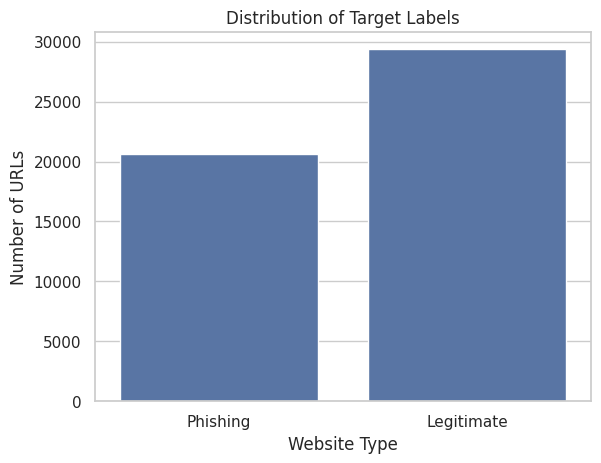

In [ ]:
# Target Distribution

sns.countplot(data=df, x="label")
plt.xticks([0, 1], ["Phishing", "Legitimate"])
plt.title("Distribution of Target Labels")
plt.xlabel("Website Type")
plt.ylabel("Number of URLs")
plt.show()


### Interpretation of Target Distribution

The dataset contains 20,625 phishing websites (41.25%) and 29,374 legitimate websites (58.75%).

Legitimate websites are more common than phishing websites, indicating a moderate class imbalance.

### Key Findings

- Legitimate websites represent the majority of the dataset.
- Phishing websites account for a significant portion (41.25%).
- The class imbalance should be considered when developing phishing detection models.


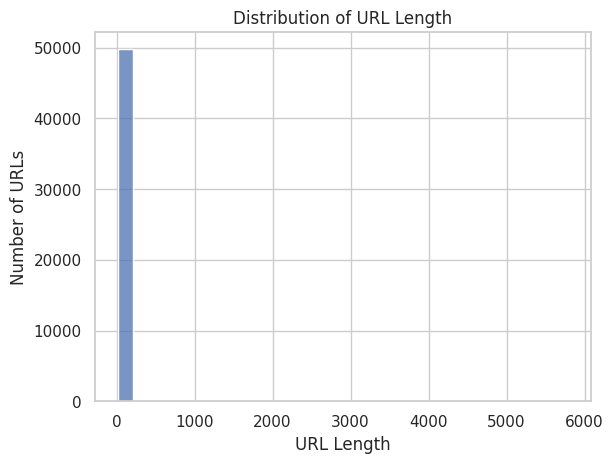

In [ ]:

# Analyze URL Length Distribution

sns.histplot(df["URLLength"], bins=30)
plt.title("Distribution of URL Length")
plt.xlabel("URL Length")
plt.ylabel("Number of URLs")
plt.show()



### Interpretation of URL Length Distribution

The distribution shows that most URLs have shorter lengths, while a smaller number of URLs are unusually long, resulting in a right-skewed distribution.

### Key Findings

- Most URLs are concentrated in the shorter length range.
- A few URLs have extremely long lengths.
- URL length can be a useful feature for identifying unusual website patterns.
- Comparing URL lengths between phishing and legitimate websites may help identify suspicious URLs.


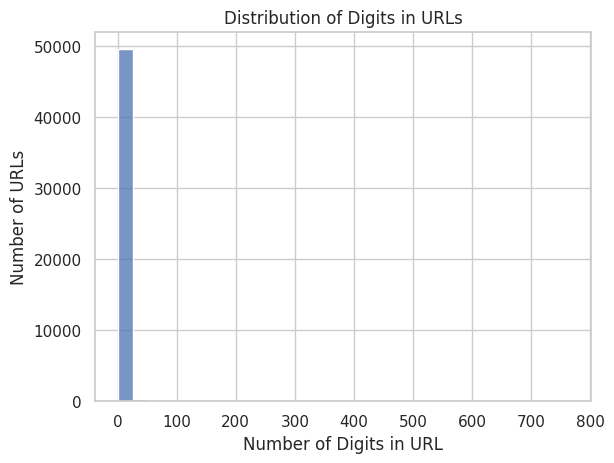

In [ ]:

# Digits in URLs Analysis

sns.histplot(df["NoOfDegitsInURL"], bins=30)
plt.title("Distribution of Digits in URLs")
plt.xlabel("Number of Digits in URL")
plt.ylabel("Number of URLs")
plt.show()



### Interpretation of Digits in URLs Analysis

The distribution shows that most URLs contain very few digits, while a smaller number contain many digits, resulting in a right-skewed distribution.

### Key Findings

- Most URLs contain fewer digits.
- Some URLs contain unusually high numbers of digits.
- Digit count may help identify unusual URL patterns.
- Comparing digit counts between phishing and legitimate websites may help identify suspicious URLs.


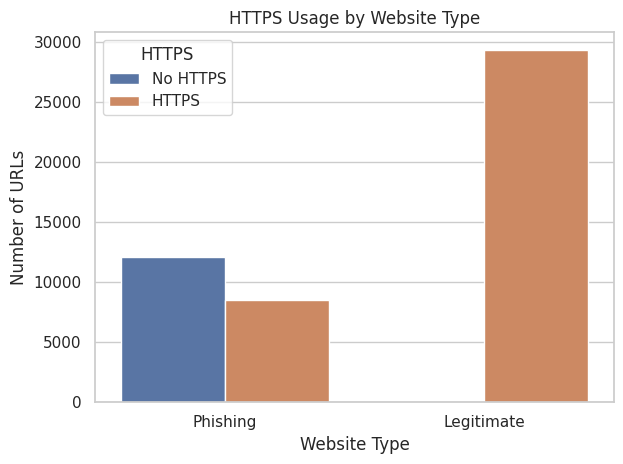

In [ ]:

# URL Security Features Analysis

sns.countplot(
    data=df,
    x="label",
    hue="IsHTTPS",
    order=[0, 1],
    hue_order=[0, 1]
)

plt.title("HTTPS Usage by Website Type")
plt.xlabel("Website Type")
plt.ylabel("Number of URLs")
plt.xticks([0, 1], ["Phishing", "Legitimate"])
plt.legend(title="HTTPS", labels=["No HTTPS", "HTTPS"])
plt.tight_layout()
plt.show()



### Interpretation of URL Security Features Analysis

The chart compares HTTPS usage between phishing and legitimate websites.

Legitimate websites show higher HTTPS adoption, while phishing websites include both HTTPS and non-HTTPS URLs.

### Key Findings

- HTTPS usage differs between phishing and legitimate websites.
- Some phishing websites also use HTTPS.
- HTTPS alone cannot confirm whether a website is safe.
- Combining HTTPS with other URL and website features may improve phishing detection.


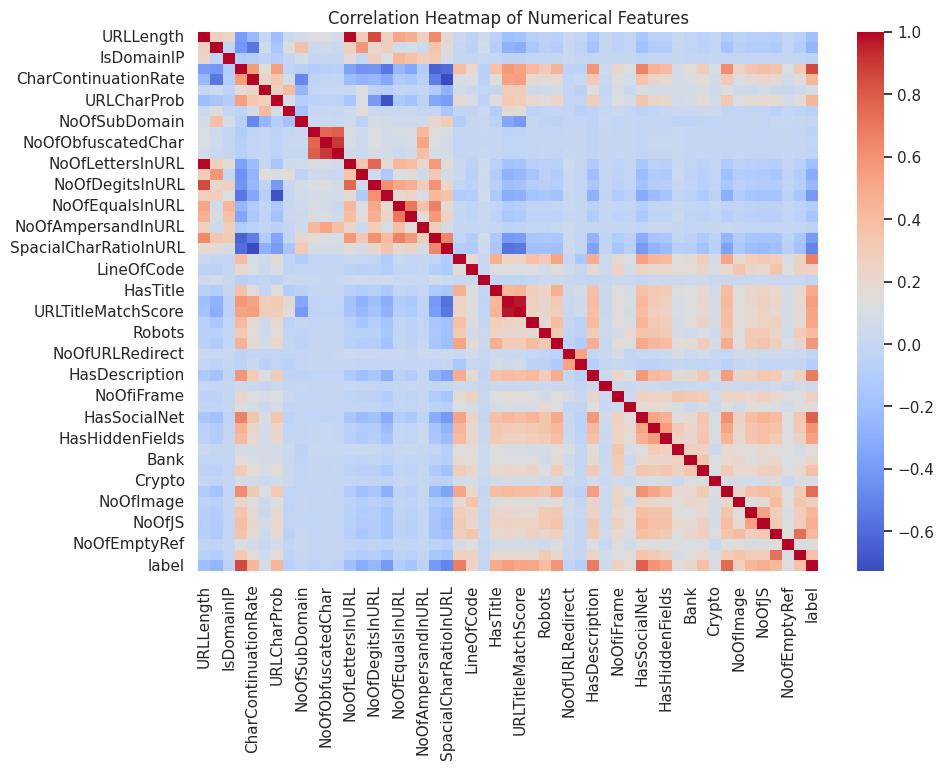

In [ ]:

# Correlation Heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(df.select_dtypes(include="number").corr(), cmap="coolwarm")

plt.title("Correlation Heatmap of Numerical Features")
plt.show()



### Interpretation of Correlation Heatmap

The correlation heatmap shows the relationships among numerical URL and website features.

Positive correlations indicate that two features tend to increase together, while negative correlations indicate that one feature tends to decrease as the other increases.

### Key Findings

- The heatmap helps identify relationships between numerical features.
- Strongly correlated features may contain similar information.
- Understanding these relationships can support feature selection for phishing detection.
- Correlation does not necessarily indicate a cause-and-effect relationship.


# Stage 3: Statistical Analysis & Visualizations

## Overview

This stage focuses on performing statistical analysis and creating visualizations to identify patterns and differences between phishing and legitimate websites.

The analysis will focus on URL structure, domain characteristics, website features, and security-related indicators based on the six project objectives.

In [ ]:

# Objective 1: URL and Domain Length Statistical Analysis

length_stats = df.groupby('label')[['URLLength', 'DomainLength']].agg(
    ['mean', 'median', 'min', 'max', 'std']
).round(2)

display(length_stats)


URLLength                         DomainLength                       
           mean median min   max    std         mean median min  max    std
label                                                                      
0         42.14   31.0  13  5794  57.66        23.70   21.0   4  110  11.43
1         26.28   26.0  16    55   4.85        19.28   19.0   9   48   4.85

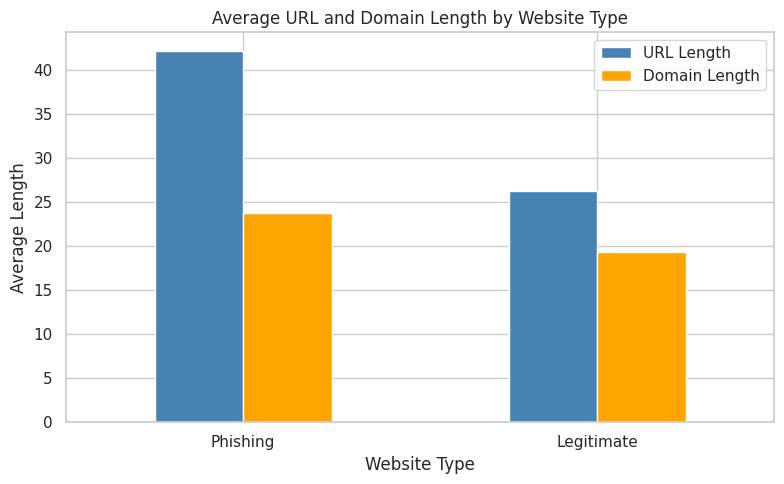

In [ ]:

# Average URL and Domain Length Comparison

avg_lengths = df.groupby('label')[
    ['URLLength', 'DomainLength']
].mean()

avg_lengths.plot(
    kind='bar',
    figsize=(8, 5),
    color=['steelblue', 'orange']
)

plt.title('Average URL and Domain Length by Website Type')
plt.xlabel('Website Type')
plt.ylabel('Average Length')
plt.xticks([0, 1], ['Phishing', 'Legitimate'], rotation=0)
plt.legend(['URL Length', 'Domain Length'])
plt.tight_layout()
plt.show()



### Interpretation of Average URL and Domain Length Comparison

The analysis shows that phishing websites have longer average URL and domain lengths compared to legitimate websites.

The average URL length is 42.14 for phishing websites and 26.28 for legitimate websites. Similarly, the average domain length is 23.70 for phishing websites and 19.28 for legitimate websites.

### Key Findings

- Phishing websites have longer URLs on average.
- Phishing websites have slightly longer domain names.
- URL and domain lengths may help identify suspicious website patterns.
- These features can support phishing detection when combined with other security indicators.


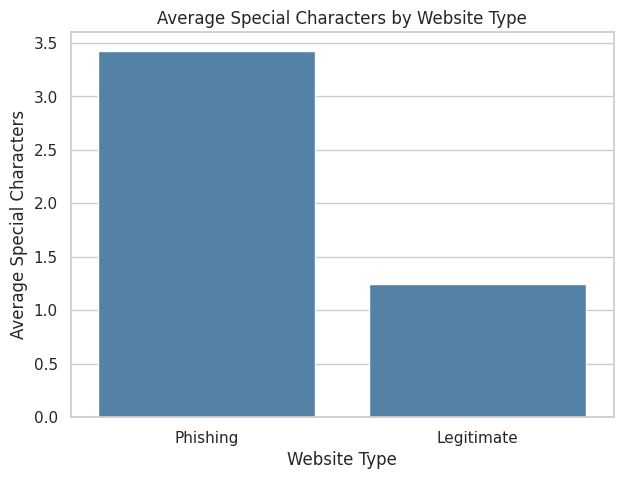

In [ ]:

# Average Special Characters by Website Label

special_chars = df.groupby('label')['NoOfOtherSpecialCharsInURL'].mean()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=special_chars.index,
    y=special_chars.values,
    color='steelblue'
)

plt.title('Average Special Characters by Website Type')
plt.xlabel('Website Type')
plt.xticks([0, 1], ['Phishing', 'Legitimate'], rotation=0)
plt.ylabel('Average Special Characters')

plt.show()



### Interpretation of Average Special Characters by Website Type

The chart shows that phishing URLs contain more special characters than legitimate URLs.

Phishing URLs have an average of 3.43 special characters, while legitimate URLs have an average of 1.24.

### Key Findings

- Phishing URLs contain more special characters on average.
- Special characters may help identify suspicious URLs.
- Special characters alone cannot confirm a phishing website.
- Combining special character counts with other URL features may support phishing detection.


In [ ]:

# Objective 3: Subdomain Statistical Analysis

subdomain_stats = df.groupby('label')['NoOfSubDomain'].agg(
    ['mean', 'median', 'min', 'max', 'std']
).round(2)

subdomain_stats.index = ['Phishing', 'Legitimate']

display(subdomain_stats)



,mean,median,min,max,std
Phishing,1.18,1.0,0,10,0.74
Legitimate,1.16,1.0,1,4,0.40


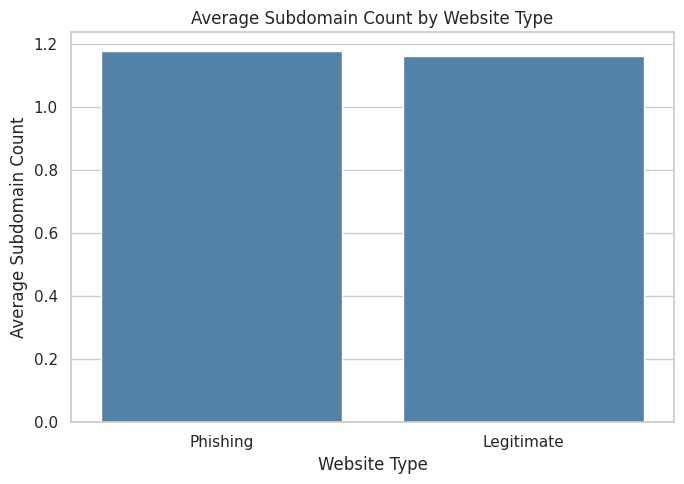

In [ ]:

# Objective 3: Average Subdomain Count by Website Type

subdomain_avg = df.groupby('label')['NoOfSubDomain'].mean()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=['Phishing', 'Legitimate'],
    y=subdomain_avg.values,
    color='steelblue'
)

plt.title('Average Subdomain Count by Website Type')
plt.xlabel('Website Type')
plt.ylabel('Average Subdomain Count')
plt.tight_layout()
plt.show()





---


### Interpretation of Subdomain Statistical Analysis

The statistical analysis and bar chart show that phishing and legitimate websites have nearly the same average number of subdomains.

Phishing websites have an average of 1.18 subdomains, while legitimate websites have an average of 1.16.

### Key Findings

- Phishing websites have a slightly higher average subdomain count.
- The difference between both website types is very small.
- Subdomain count alone is not a strong indicator of phishing websites.
- Subdomain count may be more useful when combined with other URL and website features.


In [ ]:

# Objective 4: URL Similarity and Domain-Title Matching Analysis

similarity_stats = df.groupby('label')[
    ['URLSimilarityIndex', 'DomainTitleMatchScore']
].agg(['mean', 'median', 'min', 'max', 'std']).round(2)

similarity_stats.index = ['Phishing', 'Legitimate']

display(similarity_stats)


URLSimilarityIndex                               \
                         mean  median     min    max   std   
Phishing                52.69   55.56    0.16  100.0  22.3   
Legitimate             100.00  100.00  100.00  100.0   0.0   

           DomainTitleMatchScore                            
                            mean median  min    max    std  
Phishing                   19.76    0.0  0.0  100.0  39.50  
Legitimate                 75.44  100.0  0.0  100.0  42.57

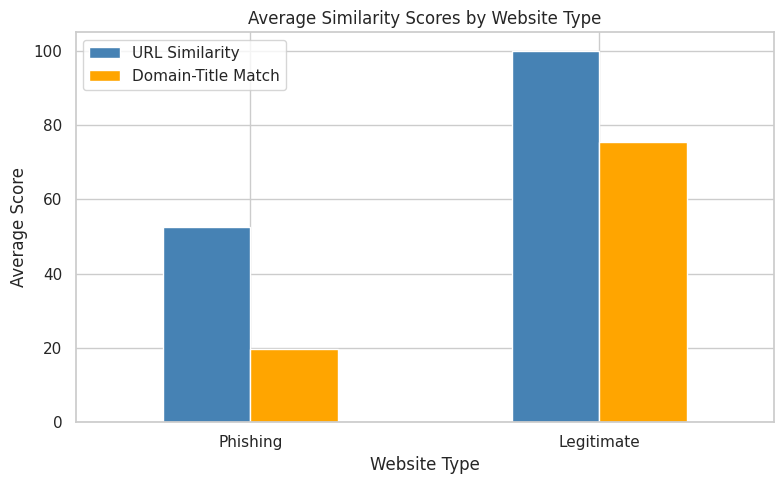

In [ ]:

# Average Similarity Scores by Website Type

avg_scores = df.groupby('label')[
    ['URLSimilarityIndex', 'DomainTitleMatchScore']
].mean()

avg_scores.plot(
    kind='bar',
    figsize=(8, 5),
    color=['steelblue', 'orange']
)

plt.title('Average Similarity Scores by Website Type')
plt.xlabel('Website Type')
plt.ylabel('Average Score')
plt.xticks([0, 1], ['Phishing', 'Legitimate'], rotation=0)
plt.legend(['URL Similarity', 'Domain-Title Match'])
plt.tight_layout()
plt.show()



### Interpretation of URL Similarity and Domain-Title Matching Analysis

The analysis shows that legitimate websites have higher URL similarity and domain-title matching scores compared to phishing websites.

The average URL similarity score is 52.69 for phishing websites and 100 for legitimate websites.

The average domain-title matching score is 19.76 for phishing websites and 75.44 for legitimate websites.

### Key Findings

- Legitimate websites have higher URL similarity scores.
- Legitimate websites have stronger domain-title matching scores.
- These features may help distinguish phishing websites from legitimate websites.
- Lower similarity and domain-title matching scores may indicate suspicious website characteristics.
- Combining these features with other URL and security indicators may support phishing detection.


In [ ]:

# Objective 5: Website Features Statistical Analysis

website_features = [
    'HasTitle',
    'HasFavicon',
    'HasDescription',
    'HasPasswordField'
]

feature_stats = df.groupby('label')[website_features].mean().mul(100).round(2)

feature_stats.index = ['Phishing', 'Legitimate']

display(feature_stats)


,HasTitle,HasFavicon,HasDescription,HasPasswordField
Phishing,64.80,7.25,4.22,4.13
Legitimate,99.87,56.96,73.65,13.88


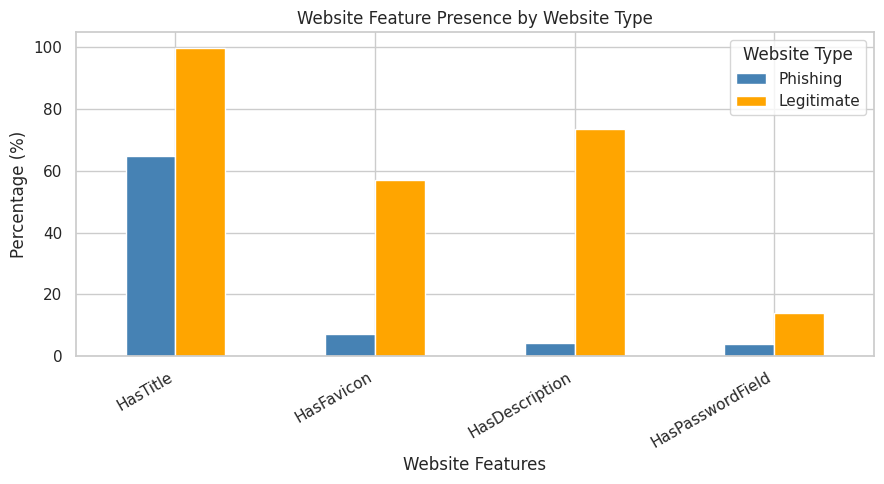

In [ ]:

# Objective 5: Website Features Comparison

feature_stats.T.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'orange']
)

plt.title('Website Feature Presence by Website Type')
plt.xlabel('Website Features')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Website Type')
plt.tight_layout()
plt.show()



### Interpretation of Website Features Analysis

The analysis shows that legitimate websites have a higher presence of titles, favicons, descriptions, and password fields compared to phishing websites.

Website titles are present in 99.87% of legitimate websites and 64.80% of phishing websites.

Website descriptions are present in 73.65% of legitimate websites and only 4.22% of phishing websites.

### Key Findings

- Legitimate websites have higher presence rates for all four analyzed website features.
- Website titles and descriptions show noticeable differences between phishing and legitimate websites.
- Favicons are also more common among legitimate websites.
- The presence of password fields alone does not indicate phishing.
- Combining these website features with other URL characteristics may support phishing detection.


In [ ]:

# Objective 6: HTTPS and Security Indicators Analysis

security_stats = df.groupby('label')[
    ['IsHTTPS', 'IsDomainIP', 'NoOfURLRedirect']
].agg(['mean', 'median', 'max']).round(2)

security_stats.index = ['Phishing', 'Legitimate']

display(security_stats)



IsHTTPS            IsDomainIP            NoOfURLRedirect           
              mean median max       mean median max            mean median max
Phishing      0.41    0.0   1        0.0    0.0   1            0.15    0.0   1
Legitimate    1.00    1.0   1        0.0    0.0   0            0.12    0.0   1

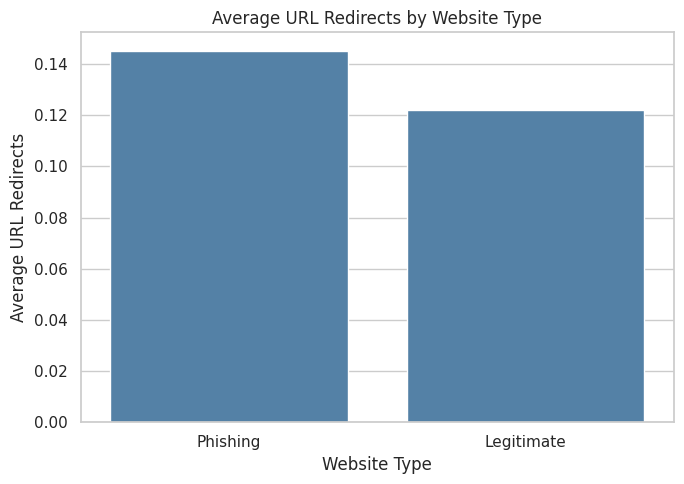

In [ ]:

# Objective 6: Average URL Redirects by Website Type

redirect_avg = df.groupby('label')['NoOfURLRedirect'].mean()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=['Phishing', 'Legitimate'],
    y=redirect_avg.values,
    color='steelblue'
)

plt.title('Average URL Redirects by Website Type')
plt.xlabel('Website Type')
plt.ylabel('Average URL Redirects')
plt.tight_layout()
plt.show()




### Interpretation of HTTPS and Security Indicators Analysis

The statistical analysis compares HTTPS usage, IP-based domains, and URL redirects between phishing and legitimate websites.

The bar chart shows that phishing websites have an average of 0.15 URL redirects, while legitimate websites have an average of 0.12.

### Key Findings

- Phishing websites have slightly more URL redirects on average.
- The difference in average redirects is very small.
- HTTPS usage, IP-based domains, and URL redirects provide useful information about website characteristics.
- These indicators alone cannot confirm whether a website is phishing.
- Combining multiple URL and security features may support more effective phishing detection.



# Predictive Analysis — Phishing Website Classification


##Feature Selection

Select relevant numerical features from the cleaned dataset to predict whether a website is phishing or legitimate.



In [ ]:

# Feature Selection

X = df.select_dtypes(include="number").drop(columns=["label", "URLLengthCategory"], errors="ignore")

# Target variable
y = df["label"]

print("Total Features:", X.shape[1])
print("Feature Names:")
print(X.columns.tolist())


Total Features: 50
Feature Names:
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']



##Train-Test Split

The dataset is divided into 80% training data and 20% testing data to train and evaluate the machine learning model.


In [ ]:

# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (39999, 50)
Testing Data: (10000, 50)



## Model Training — Logistic Regression

A Logistic Regression model is trained using the selected website features to classify websites as phishing or legitimate.


In [ ]:

# Model Training — Logistic Regression

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Scale features and train the model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully")


Logistic Regression Model Trained Successfully



##Prediction

The trained Logistic Regression model is used to predict whether websites in the testing dataset are phishing or legitimate.


In [ ]:

# Prediction

y_pred = model.predict(X_test)

print("Total Predictions:", len(y_pred))

print("\nFirst 10 Predictions:")
print(y_pred[:10])


Total Predictions: 10000

First 10 Predictions:
[0 0 1 1 1 1 0 1 1 1]



##Model Evaluation

The performance of the Logistic Regression model is evaluated using Accuracy, Precision, Recall, and F1-Score to measure its effectiveness in classifying phishing and legitimate websites.


In [ ]:

# Model Evaluation

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred, pos_label=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, y_pred, pos_label=0) * 100, 2), "%")
print("F1-Score:", round(f1_score(y_test, y_pred, pos_label=0) * 100, 2), "%")


Accuracy: 99.98 %
Precision: 100.0 %
Recall: 99.95 %
F1-Score: 99.98 %



##Confusion Matrix Visualization

A confusion matrix is used to visualize the classification performance of the Logistic Regression model by comparing actual and predicted website labels.


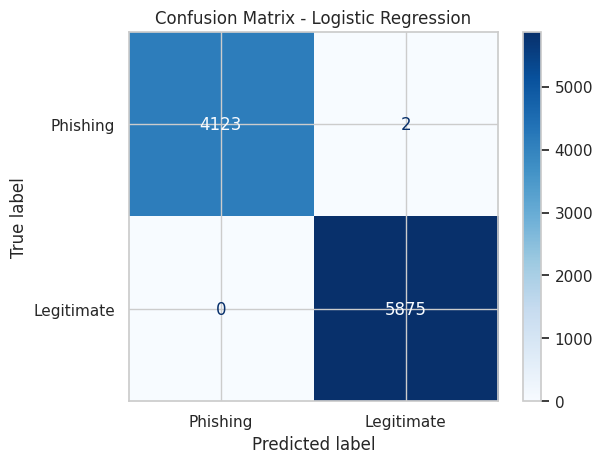

In [ ]:

# Confusion Matrix Visualization

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Phishing", "Legitimate"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()



## Step 7: Interpretation & Insights

The Logistic Regression model achieved an accuracy of **99.98%** on the testing dataset, correctly classifying 9,998 out of 10,000 websites.

### Key Findings

1. **High Classification Accuracy:** The model achieved 99.98% accuracy, with only 2 incorrect predictions.

2. **Excellent Phishing Precision:** The precision of 100% indicates that every website predicted as phishing was actually phishing in the testing dataset.

3. **High Phishing Recall:** The recall of 99.95% shows that the model successfully identified 4,123 out of 4,125 phishing websites.

4. **Strong F1-Score:** The F1-score of 99.98% indicates an excellent balance between phishing precision and recall.

5. **Confusion Matrix Findings:** The model correctly classified 4,123 phishing websites and 5,875 legitimate websites. However, 2 phishing websites were incorrectly classified as legitimate.

### Conclusion

The Logistic Regression model demonstrated excellent classification performance on the testing dataset. However, the two missed phishing websites highlight the importance of minimizing false negatives in cybersecurity applications.

The unusually high performance also requires further validation for potential data leakage and generalization to unseen websites before the model can be considered reliable for real-world deployment.


In [ ]:

# Feature Leakage Validation - Step 1

features_to_check = [
    "URLSimilarityIndex",
    "TLDLegitimateProb",
    "DomainTitleMatchScore",
    "URLTitleMatchScore"
]

print(df.groupby("label")[features_to_check].mean().round(2))


       URLSimilarityIndex  TLDLegitimateProb  DomainTitleMatchScore  \
label                                                                 
0                   52.69               0.24                  19.76   
1                  100.00               0.28                  75.44   

       URLTitleMatchScore  
label                      
0                   23.71  
1                   75.44  



### URLSimilarityIndex Distribution Analysis

This analysis examines the distribution of URLSimilarityIndex across phishing and legitimate websites to identify whether the feature may provide unusually strong information about the target label.


In [ ]:

# URLSimilarityIndex Distribution Analysis

print("URLSimilarityIndex Distribution by Label:")

print(
    df.groupby("label")["URLSimilarityIndex"]
    .agg(["min", "max", "mean", "std"])
    .round(2)
)

print("\nWebsites with URLSimilarityIndex = 100:")

print(
    pd.crosstab(
        df["label"],
        df["URLSimilarityIndex"] == 100
    )
)


URLSimilarityIndex Distribution by Label:
          min    max    mean   std
label                             
0        0.16  100.0   52.69  22.3
1      100.00  100.0  100.00   0.0

Websites with URLSimilarityIndex = 100:
URLSimilarityIndex  False  True 
label                           
0                   20417    208
1                       0  29374



###Model Validation Without URLSimilarityIndex

To assess the influence of URLSimilarityIndex on model performance, a separate Logistic Regression model is trained without this feature. The results are compared with the original model to evaluate its impact on classification accuracy.


In [ ]:

# Model Validation Without URLSimilarityIndex

X_train_check = X_train.drop(columns=["URLSimilarityIndex"])
X_test_check = X_test.drop(columns=["URLSimilarityIndex"])

validation_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

validation_model.fit(X_train_check, y_train)
y_pred_check = validation_model.predict(X_test_check)

print("Original Model Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Validation Model Accuracy:",
      round(accuracy_score(y_test, y_pred_check) * 100, 2), "%")

print("Validation Model Phishing Recall:",
      round(recall_score(y_test, y_pred_check, pos_label=0) * 100, 2), "%")


Original Model Accuracy: 99.98 %
Validation Model Accuracy: 99.9 %
Validation Model Phishing Recall: 99.81 %



### Step 4: Model Performance Comparison & Interpretation

The original Logistic Regression model achieved 99.98% accuracy and 99.95% phishing recall using 50 numerical features.

After removing URLSimilarityIndex, the validation model achieved 99.90% accuracy and 99.81% phishing recall using 49 numerical features.

### Key Findings

1. Model accuracy decreased by 0.08 percentage points.
2. Phishing recall decreased by 0.14 percentage points.
3. The validation model maintained high classification performance without URLSimilarityIndex.
4. Other website features appear to provide strong predictive information.

### Interpretation

Removing URLSimilarityIndex caused only a small reduction in model performance. However, this comparison does not establish whether data leakage exists.

Further investigation of feature definitions, availability during prediction, and potential leakage from other variables is required before drawing conclusions about real-world reliability.



###Remaining Feature Review

This analysis examines the relationship between selected website features and the target label to identify potential data leakage risks and understand their predictive influence.


In [ ]:

# Remaining Feature Review

features_to_review = [
    "TLDLegitimateProb",
    "DomainTitleMatchScore",
    "URLTitleMatchScore"
]

print("Feature Statistics by Label:")

print(
    df.groupby("label")[features_to_review]
    .agg(["min", "max", "mean", "std"])
    .round(2)
)

print("\nFeature Correlation with Target:")

print(
    df[features_to_review + ["label"]]
    .corr()["label"]
    .drop("label")
    .round(3)
)


Feature Statistics by Label:
      TLDLegitimateProb                   DomainTitleMatchScore                \
                    min   max  mean   std                   min    max   mean   
label                                                                           
0                   0.0  0.52  0.24  0.26                   0.0  100.0  19.76   
1                   0.0  0.52  0.28  0.25                   0.0  100.0  75.44   

             URLTitleMatchScore                       
         std                min    max   mean    std  
label                                                 
0      39.50                0.0  100.0  23.71  42.14  
1      42.57                0.0  100.0  75.44  42.57  

Feature Correlation with Target:
TLDLegitimateProb        0.088
DomainTitleMatchScore    0.553
URLTitleMatchScore       0.515
Name: label, dtype: float64



### Step 6: Additional Model Validation

A separate Logistic Regression model is trained after excluding selected features that require further leakage investigation. Its performance is compared with the original model to assess how strongly the classification results depend on these features.


In [ ]:

# Additional Model Validation

features_to_remove = [
    "URLSimilarityIndex",
    "TLDLegitimateProb",
    "DomainTitleMatchScore",
    "URLTitleMatchScore"
]

X_train_final = X_train.drop(columns=features_to_remove)
X_test_final = X_test.drop(columns=features_to_remove)

final_validation_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

final_validation_model.fit(X_train_final, y_train)
y_pred_final = final_validation_model.predict(X_test_final)

print("Original Model Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Final Validation Accuracy:",
      round(accuracy_score(y_test, y_pred_final) * 100, 2), "%")

print("Final Validation Phishing Recall:",
      round(recall_score(y_test, y_pred_final, pos_label=0) * 100, 2), "%")


Original Model Accuracy: 99.98 %
Final Validation Accuracy: 99.92 %
Final Validation Phishing Recall: 99.83 %



### Step 7: Final Validation Interpretation

The original Logistic Regression model achieved 99.98% accuracy and 99.95% phishing recall using 50 numerical features.

To assess the influence of potentially problematic features, four variables were excluded: URLSimilarityIndex, TLDLegitimateProb, DomainTitleMatchScore, and URLTitleMatchScore.

The validation model achieved **99.92% accuracy** and **99.83% phishing recall** using the remaining 46 features.

#### Key Findings

1. Accuracy decreased by only 0.06 percentage points after removing four selected features.
2. Phishing recall decreased by 0.12 percentage points.
3. The validation model maintained high classification performance using 46 features.
4. The results suggest that predictive information is distributed across multiple website characteristics.

#### Conclusion

The sensitivity analysis showed that the Logistic Regression model maintained high test-set performance after removing four selected features.

However, these results do not rule out data leakage from other variables or guarantee performance on new, independent websites. Further validation of feature definitions, dataset construction, and generalization is recommended before real-world deployment.



### Stage 4:Documentation, Insights & Presentation


## Step 1: Project Summary

This project analyzes phishing and legitimate websites using Python to identify patterns in URL structures, domain characteristics, security indicators, and website features.

The analysis was conducted using a sample of 49,999 records from the PhiUSIIL Phishing URL Dataset.

Exploratory Data Analysis (EDA) was performed to understand the differences between phishing and legitimate websites.

A Logistic Regression model was developed to classify websites based on their characteristics. The original model achieved 99.98% test accuracy.

Additional feature sensitivity analysis was performed by excluding four selected features. The validation model achieved 99.92% accuracy and 99.83% phishing recall.

The results demonstrate strong classification performance on the sampled dataset, although further independent validation is required to assess real-world reliability.



## Step 2: Key Findings

### 1. URL and Domain Length

Phishing websites had a higher average URL length (42.14) compared to legitimate websites (26.28).

The average domain length was also higher for phishing websites (23.70) than legitimate websites (19.28).

**Insight:** Longer URLs and domains were more common among phishing websites in the analyzed dataset.

### 2. Special Characters in URLs

Phishing websites contained an average of 3.43 special characters, compared to 1.24 for legitimate websites.

**Insight:** A higher number of special characters may be a useful indicator of potentially suspicious URLs.

### 3. Domain and Website Title Matching

Legitimate websites had higher average DomainTitleMatchScore (75.44) and URLTitleMatchScore (75.44).

Phishing websites recorded lower averages of 19.76 and 23.71, respectively.

**Insight:** Lower matching scores were associated with phishing websites in this dataset.

### 4. Website Features

Legitimate websites showed a higher presence of common website features:

- Website Title: 99.87% legitimate vs. 64.80% phishing.
- Favicon: 56.96% legitimate vs. 7.25% phishing.
- Description: 73.65% legitimate vs. 4.22% phishing.

**Insight:** The presence of common website features differed substantially between phishing and legitimate websites.

### 5. Predictive Model Performance

The original Logistic Regression model achieved 99.98% accuracy and 99.95% phishing recall on the test dataset.

After excluding four selected features, the validation model achieved 99.92% accuracy and 99.83% phishing recall.

**Insight:** The model demonstrated strong performance on the sampled dataset, but additional independent testing and feature leakage checks are required before real-world deployment.



## Step 3: Types of Analysis Performed

### 1. Descriptive Analysis — What Happened?

Analyzed 49,999 website records to understand the distribution of phishing and legitimate websites.

- Phishing Websites: 20,625 (41.25%)
- Legitimate Websites: 29,374 (58.75%)

Examined URL length, domain characteristics, HTTPS usage, and website features using summary statistics and visualizations.

### 2. Diagnostic Analysis — What Factors Are Associated?

Compared phishing and legitimate websites to identify characteristics associated with phishing.

- Phishing websites had longer URLs and more special characters on average.
- Lower domain-title and URL-title matching scores were associated with phishing websites.
- Website features such as favicons and descriptions showed noticeable differences between the two categories.

These findings identify associations but do not establish the causes of phishing.

### 3. Predictive Analysis — What Might Happen?

Developed a Logistic Regression classification model to predict whether a website is phishing or legitimate.

- Original Model Accuracy: 99.98%
- Original Model Phishing Recall: 99.95%
- Validation Model Accuracy: 99.92%
- Validation Model Phishing Recall: 99.83%

The model demonstrated strong classification performance on the sampled test data. Further independent validation is necessary to assess its ability to identify new phishing websites.

### 4. Prescriptive Analysis — What Should Be Done?

Based on the analysis, the following actions are recommended:

- Evaluate multiple URL and website characteristics rather than relying on a single indicator.
- Treat unusual URL structures and low domain-title matching scores as potential warning signals.
- Avoid assuming that HTTPS alone guarantees website legitimacy.
- Conduct additional model validation before considering deployment in real-world phishing detection systems.

These are recommendations derived from the analysis, not outcomes of a deployed detection system.



## Step 4: Recommendations & Decision Support

### Recommendations

1. **Analyze URL Characteristics**
   - Examine URL length, domain length, and special characters to identify potentially suspicious websites.
   - Avoid classifying websites based on URL length alone.

2. **Evaluate Domain and Website Features**
   - Consider domain-title matching, URL-title matching, and the presence of website descriptions and favicons.
   - Use multiple indicators together to support phishing detection.

3. **Avoid Relying Only on HTTPS**
   - HTTPS indicates an encrypted connection but does not guarantee that a website is legitimate.
   - Combine HTTPS information with other URL and website characteristics.

4. **Improve Model Reliability**
   - Validate the model using independent and more recent website data.
   - Investigate potential feature leakage and verify that all selected features are available during prediction.
   - Monitor false negatives because missed phishing websites may expose users to security risks.

### Decision Support

The analysis can support cybersecurity decision-making by:

- Highlighting website characteristics associated with phishing.
- Helping prioritize potentially suspicious URLs for further investigation.
- Providing a baseline classification model for future development.
- Supporting the design of a multi-feature phishing detection approach.

### Expected Benefits

These recommendations could help improve phishing risk assessment and guide the development of more reliable detection systems.

However, the proposed benefits have not been evaluated through real-world deployment.



## Step 5: Future Enhancements

The following improvements can be considered to enhance the accuracy, reliability, and practical applicability of the phishing website detection model.

### 1. Expand the Dataset

- Include more recent phishing and legitimate website records.
- Use datasets from multiple sources to improve diversity and generalization.

### 2. Compare Machine Learning Models

- Evaluate additional algorithms such as Random Forest, Decision Tree, and XGBoost.
- Compare models using accuracy, precision, recall, F1-score, and confusion matrices.

### 3. Improve Feature Selection

- Investigate potentially misleading or label-dependent features.
- Apply feature selection techniques to identify the most useful predictors.
- Verify that selected features can be calculated for new websites during prediction.

### 4. Strengthen Model Validation

- Test the model using independent datasets and newly collected URLs.
- Evaluate performance on previously unseen domains.
- Investigate potential data leakage and monitor false-negative predictions.

### 5. Develop a Phishing Detection Application

- Create a simple web application using Streamlit.
- Allow users to enter a website URL and receive a phishing risk prediction.
- Add appropriate warnings and explain that predictions are not guarantees of website safety.

### Expected Outcome

These future enhancements could improve model generalization, support more reliable phishing detection, and help transform the current analytical project into a practical cybersecurity application.


## Step 6: Final Project Conclusion

This project successfully analyzed phishing and legitimate websites using Python to understand the characteristics associated with phishing websites.

Through data cleaning, exploratory data analysis, visualization, and predictive modeling, the project identified useful patterns and demonstrated the potential of machine learning in phishing website detection.

Overall, the project achieved its objectives and highlighted how data-driven techniques can support website security analysis. Further testing with real-world data can help improve the reliability of the model.